# W10D5 — Sales Forecasting Dashboard
## EDA on Indian Business Dataset

**Objective:** Explore Indian business orders, analyse monthly sales patterns, compare forecasting methods, and generate a 12-month sales forecast.

### Data sources
- `data/indian_business_orders.csv` — order-level business dataset.
- `data/monthly_sales.csv` — monthly sales time series containing simulated educational data (January 2019–December 2025).

**Important:** The monthly sales series is simulated, not verified real-world market data. It is used here to demonstrate time-series forecasting. The order-level dataset is analysed separately.

### Workflow
1. Load and validate both datasets.
2. Explore orders, revenue, profit, categories, and locations.
3. Analyse monthly sales trends and seasonality.
4. Compare a seasonal-naive baseline with Prophet using a chronological 12-month holdout.
5. Forecast the next 12 months and document business insights.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
REPORT_DIR = PROJECT_DIR / "reports"

OUTPUT_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

orders_path = DATA_DIR / "indian_business_orders.csv"
sales_path = DATA_DIR / "monthly_sales.csv"

print("Project directory:", PROJECT_DIR)
print("Orders file exists:", orders_path.exists())
print("Monthly sales file exists:", sales_path.exists())

if not orders_path.exists() or not sales_path.exists():
    raise FileNotFoundError(
        "Run Jupyter from the W10D5 project folder so the data/ directory is available."
    )


Project directory: C:\Users\DELL\Desktop\Cynaris-Internship\week 10\Cynaris-W10D5
Orders file exists: True
Monthly sales file exists: True


In [2]:
orders = pd.read_csv(orders_path)
monthly_sales = pd.read_csv(sales_path)

orders["Order Date"] = pd.to_datetime(orders["Order Date"], errors="coerce")
monthly_sales["Date"] = pd.to_datetime(monthly_sales["Date"], errors="coerce")
monthly_sales["Sales"] = pd.to_numeric(monthly_sales["Sales"], errors="coerce")

monthly_sales = (
    monthly_sales.dropna(subset=["Date", "Sales"])
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Orders shape:", orders.shape)
print("Monthly sales shape:", monthly_sales.shape)
display(orders.head())
display(monthly_sales.head())


Orders shape: (1500, 17)
Monthly sales shape: (84, 2)


,Order ID,Order Date,CustomerName,State,City,Amount,Profit,Quantity,Category,Sub-Category,Year,Month,Month_Name,Quarter,Day,Weekday,Weekday_Name
0,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,"1,275.00","-1,148.00",7,Furniture,Bookcases,2018,4,Apr,2,1,6,Sunday
1,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,66.00,-12.00,5,Clothing,Stole,2018,4,Apr,2,1,6,Sunday
2,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,8.00,-2.00,3,Clothing,Hankerchief,2018,4,Apr,2,1,6,Sunday
3,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,80.00,-56.00,4,Electronics,Electronic Games,2018,4,Apr,2,1,6,Sunday
4,B-25602,2018-04-01,Pearl,Maharashtra,Pune,168.00,-111.00,2,Electronics,Phones,2018,4,Apr,2,1,6,Sunday


,Date,Sales
0,2019-01-01,"46,738.50"
1,2019-02-01,"46,181.14"
2,2019-03-01,"51,140.40"
3,2019-04-01,"55,934.22"
4,2019-05-01,"52,072.03"


## 1. Data quality and overview

In [3]:
print("ORDER DATASET")
print("Date range:", orders["Order Date"].min(), "to", orders["Order Date"].max())
print("Duplicate rows:", orders.duplicated().sum())
display(orders.isna().sum().to_frame("Missing values"))
display(orders.describe(include="all").T)

print("\\nMONTHLY SALES DATASET")
print("Date range:", monthly_sales["Date"].min(), "to", monthly_sales["Date"].max())
print("Number of monthly observations:", len(monthly_sales))
print("Duplicate dates:", monthly_sales["Date"].duplicated().sum())
display(monthly_sales[["Date", "Sales"]].describe())
display(monthly_sales.isna().sum().to_frame("Missing values"))

if monthly_sales["Date"].duplicated().any():
    raise ValueError("Monthly sales contains duplicate dates.")
if len(monthly_sales) < 36:
    raise ValueError("At least 36 monthly observations are recommended for this exercise.")


ORDER DATASET
Date range: 2018-04-01 00:00:00 to 2019-03-31 00:00:00
Duplicate rows: 0


,Missing values
Order ID,0
Order Date,0
CustomerName,0
State,0
City,0
Amount,0
Profit,0
Quantity,0
Category,0
Sub-Category,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order ID,1500,500,B-25656,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,1500,NaN,NaN,NaN,2018-10-23 14:00:57.600000,2018-04-01 00:00:00,2018-07-26 18:00:00,2018-11-08 00:00:00,2019-01-27 00:00:00,2019-03-31 00:00:00,NaN
CustomerName,1500,332,Abhishek,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,1500,19,Madhya Pradesh,340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,1500,24,Indore,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amount,"1,500.00",NaN,NaN,NaN,287.67,4.00,45.00,118.00,322.00,"5,729.00",461.05
Profit,"1,500.00",NaN,NaN,NaN,15.97,"-1,981.00",-9.25,9.00,38.00,"1,698.00",169.14
Quantity,"1,500.00",NaN,NaN,NaN,3.74,1.00,2.00,3.00,5.00,14.00,2.18
Category,1500,3,Clothing,949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-Category,1500,17,Saree,210,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nMONTHLY SALES DATASET
Date range: 2019-01-01 00:00:00 to 2025-12-01 00:00:00
Number of monthly observations: 84
Duplicate dates: 0


,Date,Sales
count,84,84.00
mean,2022-06-16 14:17:08.571428,"84,197.17"
min,2019-01-01 00:00:00,"46,181.14"
25%,2020-09-23 12:00:00,"66,319.37"
50%,2022-06-16 00:00:00,"82,411.01"
75%,2024-03-08 18:00:00,"100,361.05"
max,2025-12-01 00:00:00,"146,686.05"
std,NaN,"23,315.12"


,Missing values
Date,0
Sales,0


## 2. Exploratory data analysis — Indian business orders

,Value
Total sales,"431,502.00"
Total profit,"23,955.00"
Total quantity,"5,615.00"
Unique orders,500.00
Average order value,863.00


,Sales,Profit,Quantity
Category,,,
Electronics,"165,267.00","10,494.00",1154
Clothing,"139,054.00","11,163.00",3516
Furniture,"127,181.00","2,298.00",945


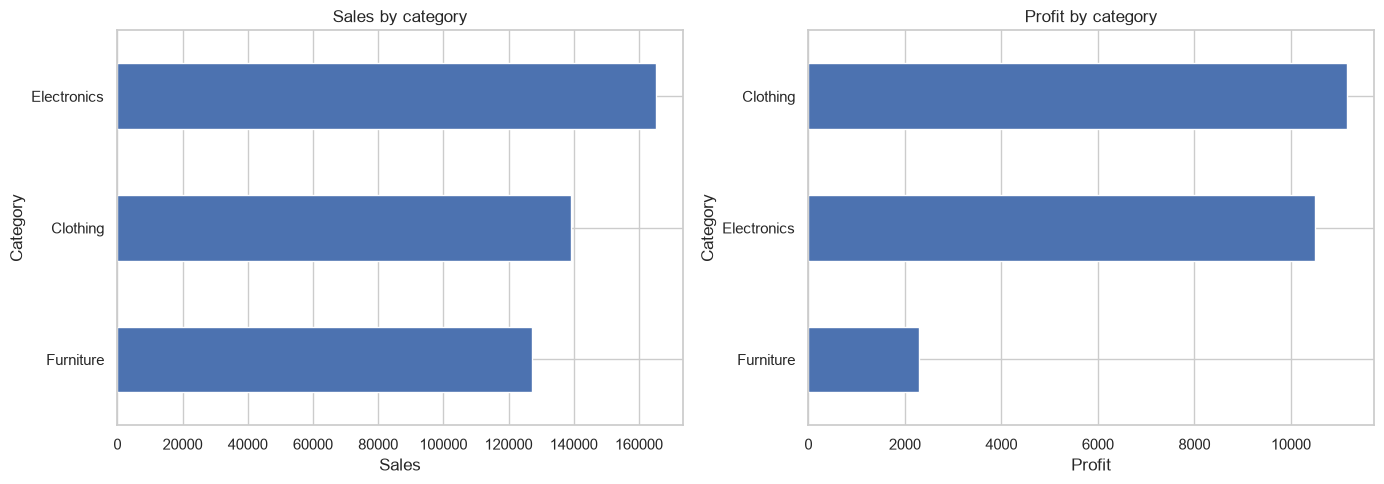

,Sales
State,
Madhya Pradesh,"105,140.00"
Maharashtra,"95,348.00"
Delhi,"22,531.00"
Uttar Pradesh,"22,359.00"
Rajasthan,"21,149.00"
Gujarat,"21,058.00"
Punjab,"16,786.00"
Karnataka,"15,058.00"
West Bengal,"14,086.00"


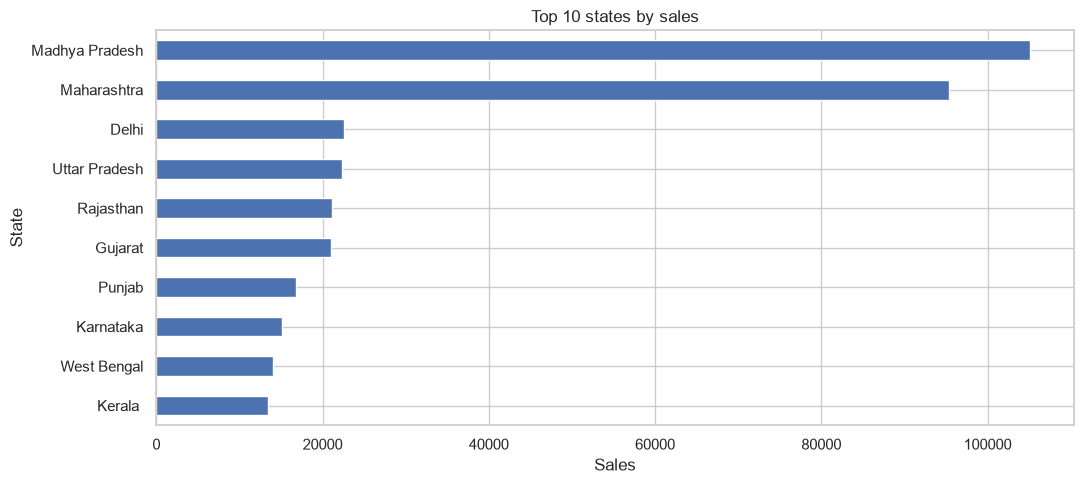

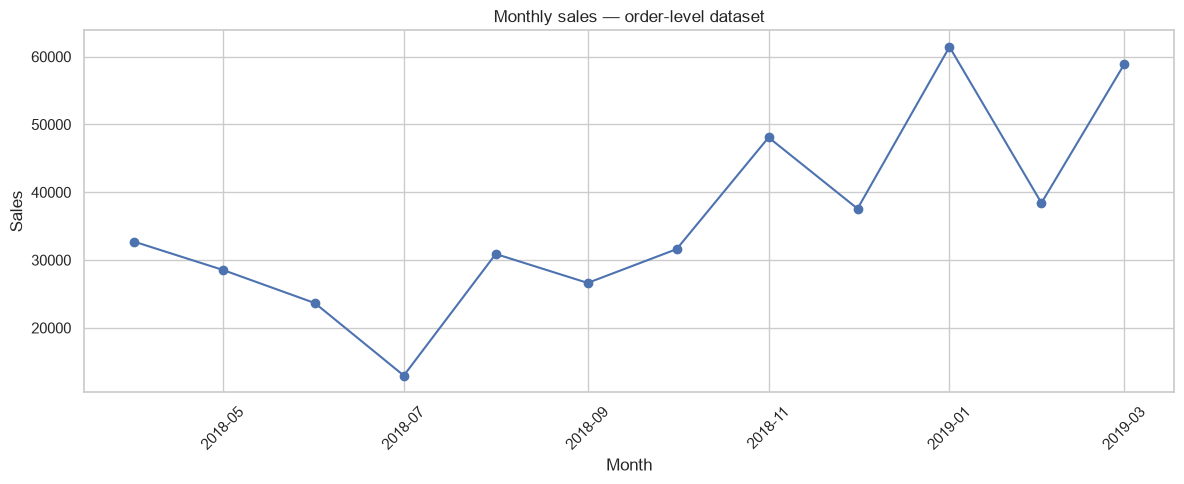

In [4]:
# Key business indicators
total_sales = orders["Amount"].sum()
total_profit = orders["Profit"].sum()
total_quantity = orders["Quantity"].sum()
order_count = orders["Order ID"].nunique()
average_order_value = total_sales / order_count if order_count else np.nan

kpis = pd.Series({
    "Total sales": total_sales,
    "Total profit": total_profit,
    "Total quantity": total_quantity,
    "Unique orders": order_count,
    "Average order value": average_order_value
}, name="Value")

display(kpis.to_frame())

# Sales and profit by category
category_summary = (
    orders.groupby("Category", dropna=False)
    .agg(Sales=("Amount", "sum"), Profit=("Profit", "sum"), Quantity=("Quantity", "sum"))
    .sort_values("Sales", ascending=False)
)
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
category_summary["Sales"].sort_values().plot(kind="barh", ax=axes[0], title="Sales by category")
category_summary["Profit"].sort_values().plot(kind="barh", ax=axes[1], title="Profit by category")
axes[0].set_xlabel("Sales")
axes[1].set_xlabel("Profit")
plt.tight_layout()
plt.show()

# Sales by state
state_summary = orders.groupby("State")["Amount"].sum().sort_values(ascending=False)
display(state_summary.head(10).to_frame("Sales"))

plt.figure(figsize=(11, 5))
state_summary.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 states by sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

# Monthly order-level sales
orders["Order Month"] = orders["Order Date"].dt.to_period("M").dt.to_timestamp()
order_monthly = orders.groupby("Order Month").agg(
    Sales=("Amount", "sum"), Profit=("Profit", "sum")
).reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(order_monthly["Order Month"], order_monthly["Sales"], marker="o")
ax.set_title("Monthly sales — order-level dataset")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 3. Time-series analysis — monthly sales

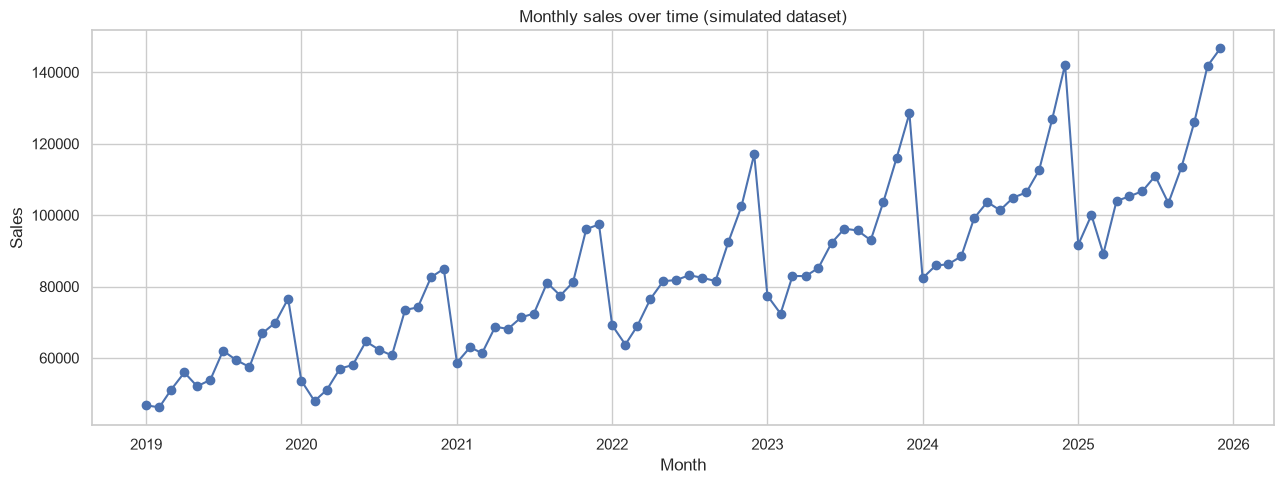

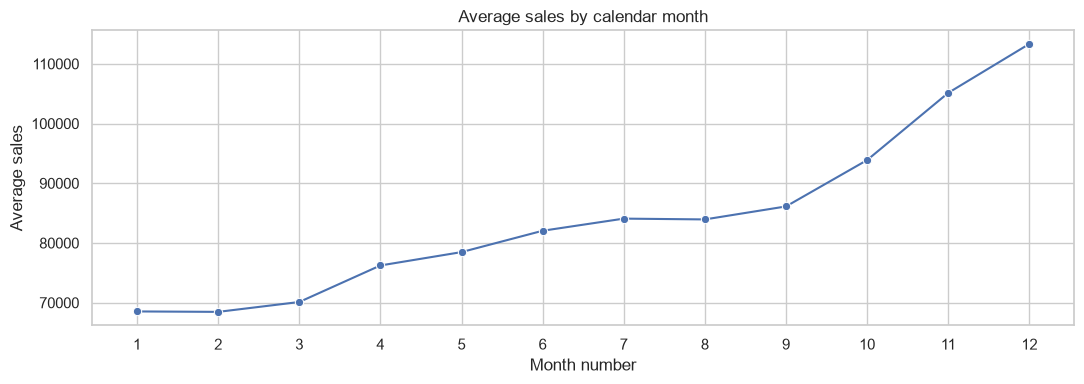

,mean,min,max
Year,,,
2019,"58,188.05","46,181.14","76,604.89"
2020,"64,220.25","47,949.30","84,959.16"
2021,"74,750.23","58,709.12","97,383.67"
2022,"83,400.23","63,748.38","117,067.40"
2023,"93,869.31","72,417.31","128,492.72"
2024,"103,349.04","82,359.03","142,172.28"
2025,"111,603.05","89,150.17","146,686.05"


,ds,y
79,2025-08-01,"103,365.20"
80,2025-09-01,"113,532.35"
81,2025-10-01,"126,087.24"
82,2025-11-01,"141,769.01"
83,2025-12-01,"146,686.05"


In [5]:
sales = monthly_sales.copy()
sales = sales.rename(columns={"Date": "ds", "Sales": "y"})

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(sales["ds"], sales["y"], marker="o", linewidth=1.5)
ax.set_title("Monthly sales over time (simulated dataset)")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.show()

sales["Year"] = sales["ds"].dt.year
sales["Month"] = sales["ds"].dt.month
sales["Month_Name"] = sales["ds"].dt.month_name()

monthly_pattern = sales.groupby("Month")["y"].mean()
plt.figure(figsize=(11, 4))
sns.lineplot(x=monthly_pattern.index, y=monthly_pattern.values, marker="o")
plt.title("Average sales by calendar month")
plt.xlabel("Month number")
plt.ylabel("Average sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

yearly_summary = sales.groupby("Year")["y"].agg(["mean", "min", "max"])
display(yearly_summary)
display(sales[["ds", "y"]].tail())


## 4. Forecast model evaluation

We reserve the **last 12 months** as a test set. Earlier observations are used for training. This preserves time order and avoids randomly mixing future observations into training.

The baseline predicts each test month using sales from the same month in the previous year. Prophet is then evaluated on exactly the same holdout period.

Metrics:
- **MAE:** average absolute prediction error.
- **RMSE:** gives larger errors more weight.
- **MAPE:** average percentage error; meaningful here because the sales values are positive.


21:29:29 - cmdstanpy - INFO - Chain [1] start processing


21:29:30 - cmdstanpy - INFO - Chain [1] done processing


,MAE,RMSE,MAPE (%)
Seasonal Naive,"8,509.66","9,777.81",7.65
Prophet,"5,533.72","6,572.27",5.24


,ds,y,Seasonal Naive,Prophet
72,2025-01-01,"91,717.98","82,359.03","99,307.89"
73,2025-02-01,"100,025.65","85,918.87","100,835.92"
74,2025-03-01,"89,150.17","86,206.14","100,817.87"
75,2025-04-01,"103,967.02","88,489.18","106,100.88"
76,2025-05-01,"105,244.42","99,108.90","109,584.27"
77,2025-06-01,"106,729.38","103,674.55","113,825.88"
78,2025-07-01,"110,962.13","101,367.24","114,167.38"
79,2025-08-01,"103,365.20","104,899.11","115,867.70"
80,2025-09-01,"113,532.35","106,371.75","118,003.93"
81,2025-10-01,"126,087.24","112,603.53","123,657.64"


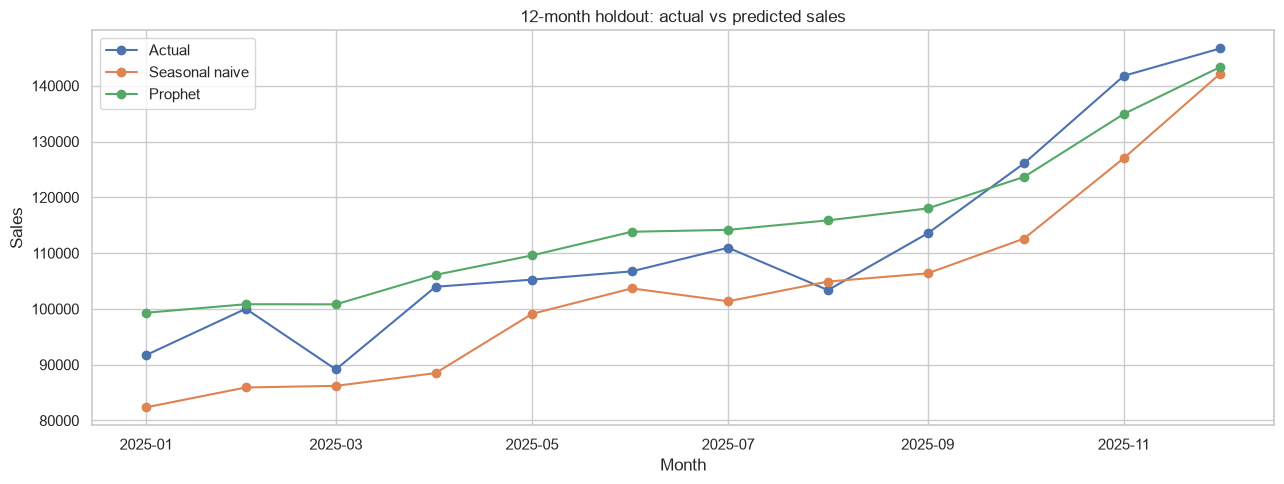

In [6]:
HOLDOUT_MONTHS = 12

train = sales[["ds", "y"]].iloc[:-HOLDOUT_MONTHS].copy()
test = sales[["ds", "y"]].iloc[-HOLDOUT_MONTHS:].copy()

# Seasonal-naive baseline: repeat the values from the previous year.
baseline_predictions = sales["y"].iloc[-2 * HOLDOUT_MONTHS:-HOLDOUT_MONTHS].to_numpy()

if len(baseline_predictions) != len(test):
    raise ValueError("Could not construct the 12-month seasonal baseline.")

# Fit Prophet only on the training period.
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode="additive"
)
model.fit(train)

prophet_predictions = model.predict(test[["ds"]])["yhat"].to_numpy()

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(np.abs((actual - predicted) / actual)) * 100
    }

comparison = pd.DataFrame({
    "Seasonal Naive": calculate_metrics(test["y"], baseline_predictions),
    "Prophet": calculate_metrics(test["y"], prophet_predictions)
}).T

display(comparison)

evaluation = test.copy()
evaluation["Seasonal Naive"] = baseline_predictions
evaluation["Prophet"] = prophet_predictions
display(evaluation)

evaluation.to_csv(OUTPUT_DIR / "w10d5_model_evaluation.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test["ds"], test["y"], marker="o", label="Actual")
ax.plot(test["ds"], baseline_predictions, marker="o", label="Seasonal naive")
ax.plot(test["ds"], prophet_predictions, marker="o", label="Prophet")
ax.set_title("12-month holdout: actual vs predicted sales")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "w10d5_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Final model and 12-month forecast

21:29:30 - cmdstanpy - INFO - Chain [1] start processing


21:29:31 - cmdstanpy - INFO - Chain [1] done processing


,Forecast Month,Predicted Sales,Lower Estimate,Upper Estimate
84,2026-01-01,"105,635.07","101,021.02","110,252.63"
85,2026-02-01,"107,200.20","102,670.23","111,611.17"
86,2026-03-01,"108,844.48","104,601.55","113,753.71"
87,2026-04-01,"114,363.75","109,309.12","119,065.96"
88,2026-05-01,"115,666.05","110,851.24","120,239.82"
89,2026-06-01,"119,167.13","114,304.92","123,590.62"
90,2026-07-01,"122,918.30","118,358.71","127,465.27"
91,2026-08-01,"122,653.54","118,085.46","127,435.51"
92,2026-09-01,"123,310.60","118,814.34","128,196.18"
93,2026-10-01,"132,544.59","127,785.59","137,161.41"


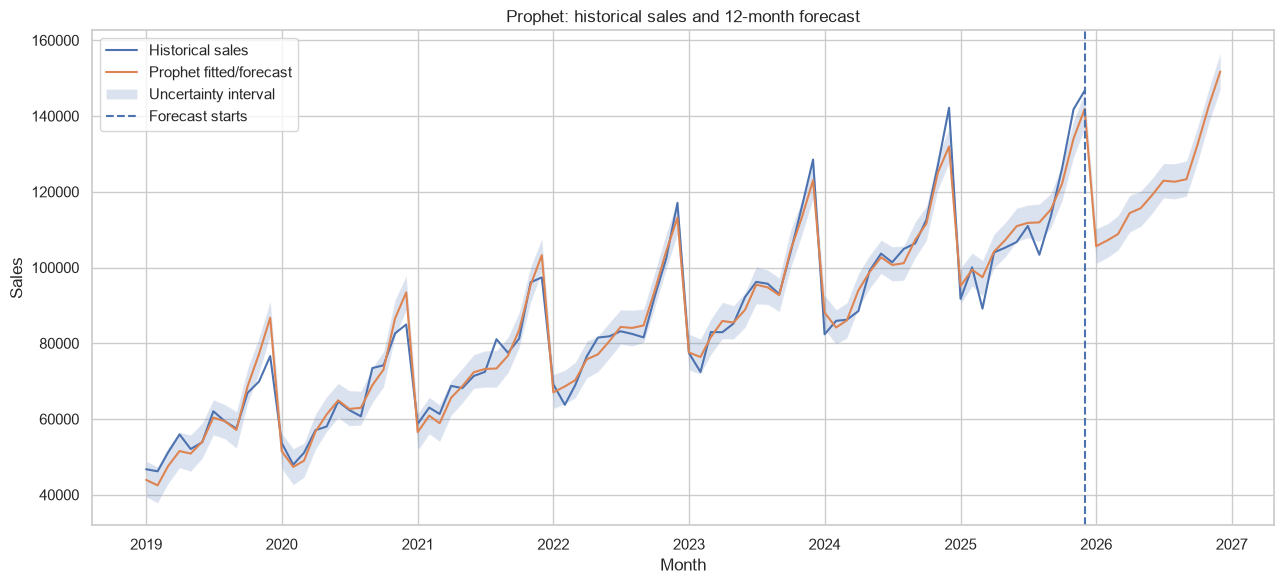

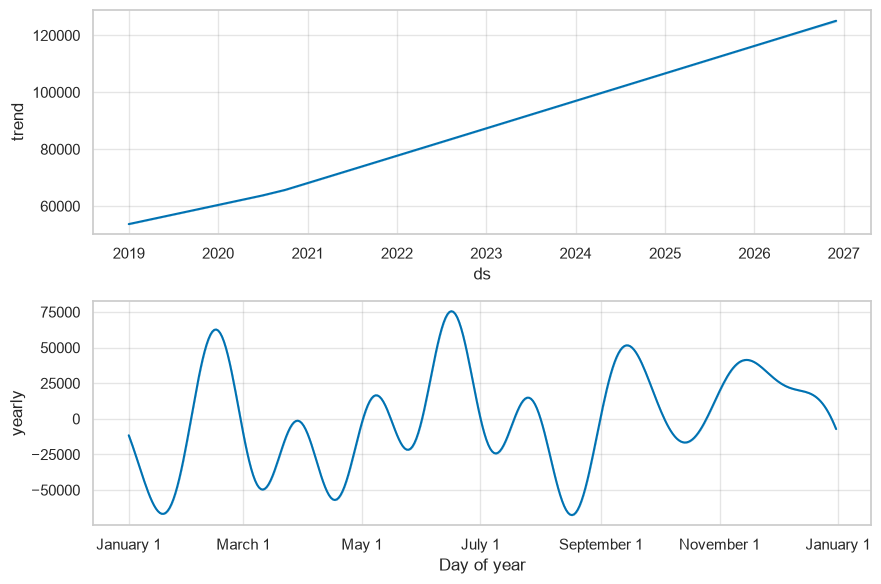

In [7]:
# Refit Prophet on all available observations for the future forecast.
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode="additive"
)
final_model.fit(sales[["ds", "y"]])

future = final_model.make_future_dataframe(periods=12, freq="MS")
forecast = final_model.predict(future)

future_forecast = forecast.loc[
    forecast["ds"] > sales["ds"].max(),
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

future_forecast = future_forecast.rename(columns={
    "ds": "Forecast Month",
    "yhat": "Predicted Sales",
    "yhat_lower": "Lower Estimate",
    "yhat_upper": "Upper Estimate"
})

future_forecast.to_csv(OUTPUT_DIR / "w10d5_12_month_forecast.csv", index=False)
display(future_forecast.round(2))

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(sales["ds"], sales["y"], label="Historical sales")
ax.plot(forecast["ds"], forecast["yhat"], label="Prophet fitted/forecast")
ax.fill_between(
    forecast["ds"],
    forecast["yhat_lower"],
    forecast["yhat_upper"],
    alpha=0.2,
    label="Uncertainty interval"
)
ax.axvline(sales["ds"].max(), linestyle="--", label="Forecast starts")
ax.set_title("Prophet: historical sales and 12-month forecast")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "w10d5_12_month_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

fig = final_model.plot_components(forecast)
fig.savefig(OUTPUT_DIR / "w10d5_forecast_components.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Findings, limitations, and conclusion

In [8]:
best_model = comparison["MAE"].idxmin()
best_mae = comparison.loc[best_model, "MAE"]

findings = [
    f"The order-level dataset contains {len(orders):,} rows and {orders['Order ID'].nunique():,} unique orders.",
    f"Total order-level sales are {total_sales:,.2f} and total profit is {total_profit:,.2f}.",
    f"The monthly time-series dataset contains {len(sales)} observations from {sales['ds'].min().date()} to {sales['ds'].max().date()}.",
    f"On the 12-month holdout, {best_model} achieved the lower MAE ({best_mae:,.2f}).",
    "The monthly sales series is simulated educational data; its patterns and forecasts must not be presented as verified real-world market predictions."
]

for item in findings:
    print("-", item)

print("\nLimitations:")
print("- The monthly time series is simulated and may not represent actual business demand.")
print("- Forecast quality depends on the historical patterns continuing into the future.")
print("- A 12-month holdout is one evaluation window; performance can vary across other periods.")
print("- Forecast intervals represent model uncertainty, not guaranteed sales ranges.")

report_text = "# W10D5 Sales Forecasting - Summary\n\n"
report_text += "\n".join(f"- {item}" for item in findings)
report_text += "\n\n## Model comparison\n"
report_text += comparison.round(3).to_string()
report_text += "\n\n## Limitations\n"
report_text += "\n".join([
    "- Monthly sales data is simulated educational data.",
    "- Forecasts are estimates, not guarantees.",
    "- Results should be re-evaluated with real, regularly updated sales data."
])

(REPORT_DIR / "w10d5_forecasting_summary.txt").write_text(report_text, encoding="utf-8")
print("\nSaved evaluation, forecast, charts, and summary under outputs/ and reports/.")


- The order-level dataset contains 1,500 rows and 500 unique orders.
- Total order-level sales are 431,502.00 and total profit is 23,955.00.
- The monthly time-series dataset contains 84 observations from 2019-01-01 to 2025-12-01.
- On the 12-month holdout, Prophet achieved the lower MAE (5,533.72).
- The monthly sales series is simulated educational data; its patterns and forecasts must not be presented as verified real-world market predictions.

Limitations:
- The monthly time series is simulated and may not represent actual business demand.
- Forecast quality depends on the historical patterns continuing into the future.
- A 12-month holdout is one evaluation window; performance can vary across other periods.
- Forecast intervals represent model uncertainty, not guaranteed sales ranges.

Saved evaluation, forecast, charts, and summary under outputs/ and reports/.
